# AdaGrad Optimizer

- The main idea is not to keep the learning rate constant, but to adapt it to the parameters. 

## Scenarios in which AdaGrad is useful than other optimizers:

1. Scale of input features are different
    - But it is not a problem for deep learning, because we usually normalize the input features to have zero mean and unit variance.
2. Features are sparse (e.g. text data, bag-of-words representation)
    - Because of sparse features, there is **elongated bowl problem**

    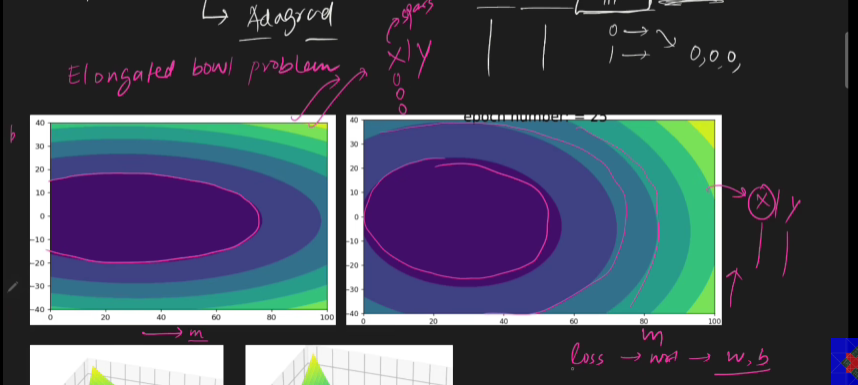

    - As you can see, the left coutour is elongated, one probable reason is that the features are sparse

- So in this elongated bowls, where gradient is very small in one direction, and very large in another direction, other optimizers does not work well, because they will come down fast in the direction of large gradient, but very small change in the direction of small gradient, and it will take a long time to reach the minimum.

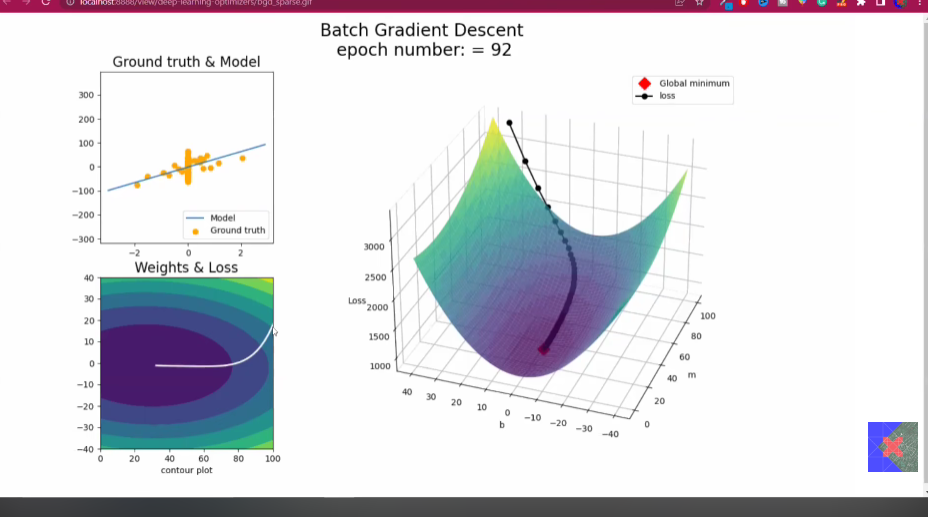

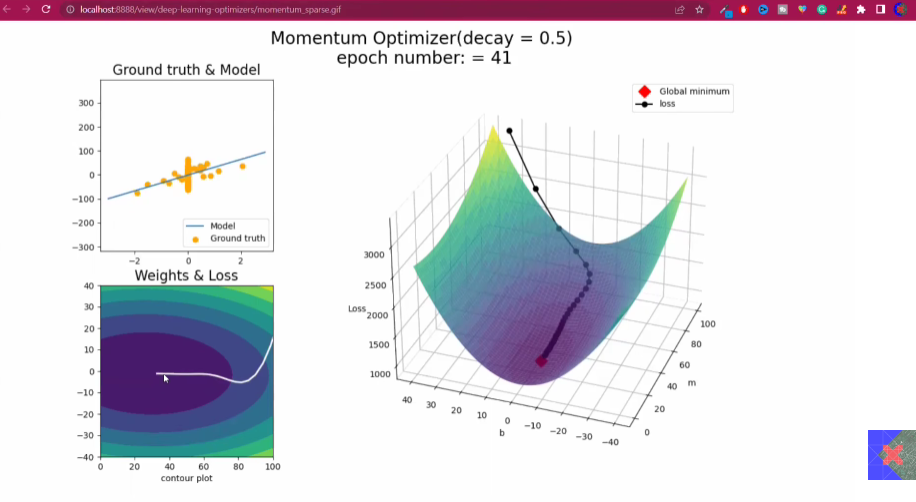

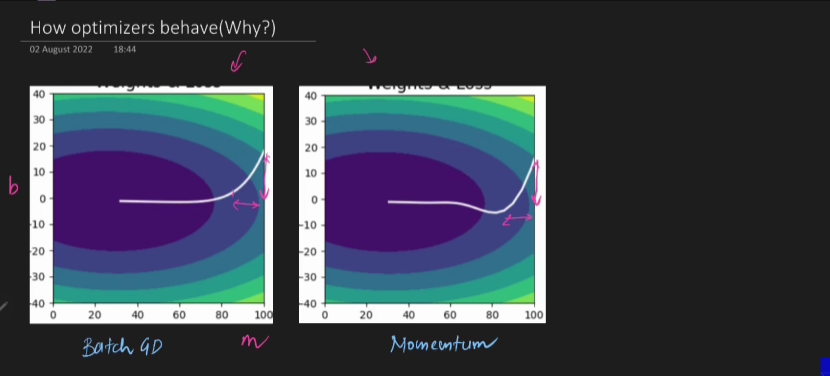

- In the figures above, the updates move mostly along $b$ (the y-axis) and only slowly along $m$ (the x-axis).

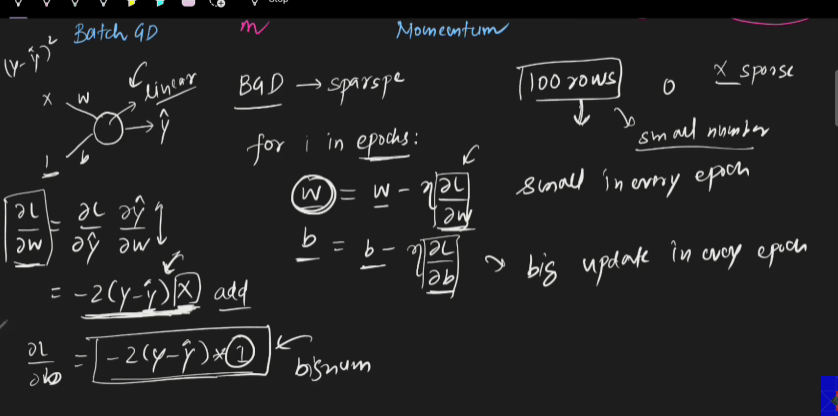

## Why updates move mostly along b and slowly along m

## Setup
- Our model is a line: $\hat{y} = mx + b$
  - $x$ = input feature
  - $m$ = weight (slope), multiplies $x$
  - $b$ = bias (intercept), added regardless of $x$
- $L$ = loss, a number that tells us how wrong the model is. For one data point:

$$
L = (\hat{y} - y)^2
$$

- Let the error be $e = \hat{y} - y$. Then $L = e^2$.
- Gradient descent updates a parameter using the slope of $L$ with respect to it.

## The two gradients
- Slope of the loss with respect to $m$:

$$
\frac{\partial L}{\partial m} = 2e \cdot x
$$

- Slope of the loss with respect to $b$:

$$
\frac{\partial L}{\partial b} = 2e
$$

- The only difference is the extra factor $x$ in the gradient of $m$.

## What happens when x is sparse
- Sparse means $x$ is $0$ for most data points.
- When $x = 0$:
  - $\frac{\partial L}{\partial m} = 2e \cdot 0 = 0$, so $m$ does not move.
  - $\frac{\partial L}{\partial b} = 2e$, which is still non-zero, so $b$ still moves.
- So $b$ is updated at almost every step, while $m$ is updated only on the few points where $x \neq 0$.

## What this does to the loss surface
- Loss is very sensitive to $b$, so the surface is steep along the $b$ axis (y-axis).
- Loss barely reacts to $m$, so the surface is flat along the $m$ axis (x-axis).
- This gives an elongated bowl, stretched along the $m$ direction.

## What this does to the updates
- Gradient descent follows the steepest direction, which is $b$.
- So in the figures, the path moves a lot along $b$ and only a little along $m$.
- Progress toward the minimum along $m$ is slow.


<hr>

# AdaGrad Mathematics + Intuition

## Problem with plain gradient descent
- Same learning rate $\eta$ for every parameter:

$$
w = w - \eta \frac{\partial L}{\partial w}, \qquad b = b - \eta \frac{\partial L}{\partial b}
$$

- Big gradient with a fixed $\eta$ gives a big update, which can overshoot.
- Small gradient with a fixed $\eta$ gives a tiny update, so learning is slow.
- Wanted: a different learning rate for each parameter.
  - Big gradient: small learning rate.
  - Small gradient: big learning rate.

## Symbols
- $\nabla w_t = \frac{\partial L}{\partial w}$ = gradient of the loss $L$ at step $t$
- $v_t$ = running sum of squared past gradients
- $\eta$ = base learning rate
- $\epsilon$ = tiny number (for example $10^{-8}$) so we never divide by zero
- $v_0 = 0$

## AdaGrad formulas

$$
v_t = v_{t-1} + (\nabla w_t)^2
$$

$$
w_{t+1} = w_t - \frac{\eta}{\sqrt{v_t + \epsilon}} \, \nabla w_t
$$

- Same formulas for $b$, with $\frac{\partial L}{\partial b}$ in place of $\frac{\partial L}{\partial w}$.

## How $v_t$ tracks past gradients
- Each step adds the square of the current gradient to $v_{t-1}$.
- So $v_t = (\nabla w_1)^2 + (\nabla w_2)^2 + \dots + (\nabla w_t)^2$.
- Squaring keeps every term positive, so gradients cannot cancel each other out.
- $v_t$ is therefore a memory of how large the gradients have been so far for that parameter.

## How $v_t$ adjusts $\eta$
- The effective learning rate is:

$$
\eta_{\text{eff}} = \frac{\eta}{\sqrt{v_t + \epsilon}}
$$

- Large past gradients: $v_t$ is big, so $\eta_{\text{eff}}$ is small.
- Small past gradients: $v_t$ is small, so $\eta_{\text{eff}}$ is big.
- Each parameter gets its own $v_t$, so each gets its own learning rate.

## Link to the sparse feature example
- $b$ gets a gradient at every step, so its $v_t$ grows fast and its learning rate shrinks.
- $m$ (sparse feature) gets few gradients, so its $v_t$ stays small and its learning rate stays larger.
- This evens out the elongated bowl: slow down along the steep direction, speed up along the flat one.

## Why $\epsilon$
- If a gradient has always been $0$, then $v_t = 0$ and we would divide by zero.
- Adding a small $\epsilon$ prevents that.


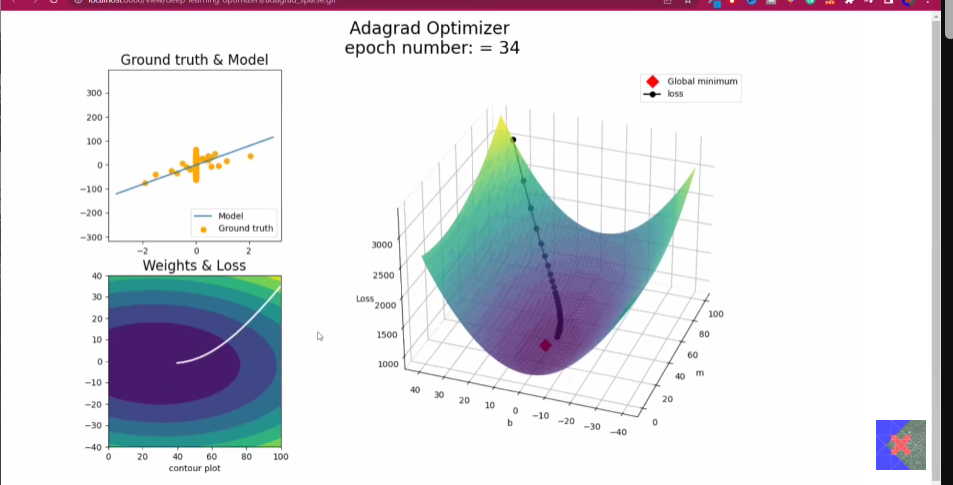

# <text style="color:orange">Very big disadvantage of AdaGrad</text>

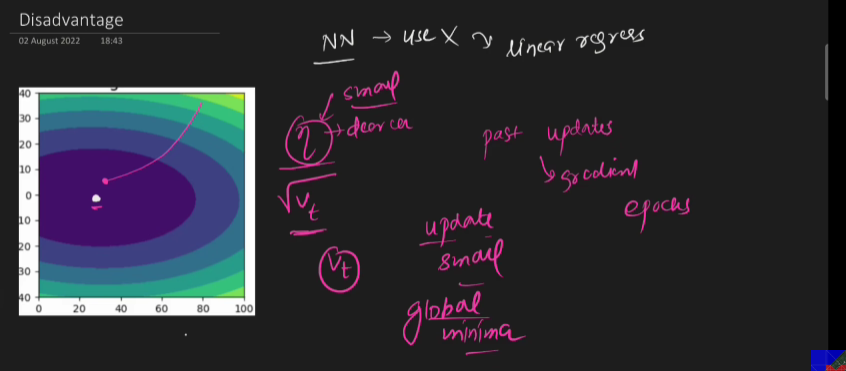

- It can never reach the global minimum, because $v_t$ only ever grows, so $\eta_{\text{eff}}$ keeps shrinking. Late in training, updates can become too small and learning stalls.

- This is the reason we never use AdaGrad in Neural Networks, but we can use it for convex optimization problems, like linear regression, logistic regression, etc.